# RQ2 — Fixation-Based Cognitive Effort (Section 4.2)

This notebook contains **all analyses reported in Section 4.2 of the current manuscript, and only those analyses**.

| Manuscript section | Analysis | Output |
|---|---|---|
| 4.2.1 | Smell vs. Clean based on participants' perception — FC, AFD, TFT | Tables 5 and 6 |
| 4.2.2 | TFT across perceived smell types — 10 paired contrasts + FDR correction | Table 7 |
| 4.2.3 | TFT for classifications consistent vs. inconsistent with the MLCQ reference labels | Table 8 + paired analysis |
| Sensitivity | Size-normalized effort (inside TFT and FC per line / per token) and size–TFT correlation | Section 6 |

**Single input:** `base_fixations_design_survey.csv` (generated by `base_fixations_design_survey.ipynb`).
A separate `snippet_metrics.csv` file is not required: FC, AFD, and TFT are derived here from the fixation-level data.

**Procedure used in all paired comparisons:**

1. aggregate fixations at the `participant × snippet` level to obtain FC, AFD, and TFT;
2. aggregate snippets within each participant and condition, yielding one value per participant and condition;
3. retain only participants with valid observations in both conditions of the contrast;
4. compare paired participant-level values using **Yuen's paired test with 20% trimming**;
5. report the **paired probability of superiority, $\hat p$**, with a 95% percentile-bootstrap confidence interval.

For families with multiple contrasts, p-values are adjusted using the Benjamini--Hochberg false-discovery-rate procedure.

**Not included:** analyses that appeared in earlier exploratory notebooks but are not part of the current manuscript, including MLCQ-defined Smell/Clean grouping, MLCQ-defined smell-type contrasts, the former `Total time` metric, the `inside` scope, and exploratory plots not retained in the manuscript.

## 0. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

# ------------------------------------------------------------
# Statistical parameters
# ------------------------------------------------------------

ALPHA = 0.05
TRIM = 0.20
N_BOOT = 10_000
SEED = 20260101


# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

NOTEBOOK_DIR = Path.cwd()

PROJECT_ROOT = NOTEBOOK_DIR.parent

ANALYSIS_DIR = PROJECT_ROOT / "analysis"

BASE_PATH = (
    PROJECT_ROOT
    / "data"
    / "base_fixations_design_survey.csv"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "rq2"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# Import shared analysis modules
# ------------------------------------------------------------

if str(ANALYSIS_DIR) not in sys.path:
    sys.path.insert(0, str(ANALYSIS_DIR))

from robust_stats import (
    benjamini_hochberg,
    paired_phat,
    paired_phat_bootstrap_ci,
    yuen_paired,
)

from utils import (
    build_group_pairs,
    participant_group_summary,
)


# ------------------------------------------------------------
# Validate paths
# ------------------------------------------------------------

if not BASE_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {BASE_PATH.resolve()}"
    )

print("Project root :", PROJECT_ROOT.resolve())
print("Dataset      :", BASE_PATH.resolve())
print("Analysis dir :", ANALYSIS_DIR.resolve())
print("Output dir   :", OUTPUT_DIR.resolve())

Project root : /home/marioless/Documents/mestrado/EoS-tosem2026/metrics_update
Dataset      : /home/marioless/Documents/mestrado/EoS-tosem2026/metrics_update/data/base_fixations_design_survey.csv
Analysis dir : /home/marioless/Documents/mestrado/EoS-tosem2026/metrics_update/analysis
Output dir   : /home/marioless/Documents/mestrado/EoS-tosem2026/metrics_update/outputs/rq2


### Helper functions

`compare_paired` receives the complete participant-level pairs for one contrast and returns the Yuen test,
paired probability of superiority, and bootstrap confidence interval in a single result record.

In [2]:
# Candidate for relocation to utils.py

def compare_paired(pairs: pd.DataFrame, comparison: str) -> dict:
    """Paired Yuen test and paired probability of superiority for an A-vs.-B contrast."""

    group_a = pairs["value_a"]
    group_b = pairs["value_b"]

    yuen = yuen_paired(group_a, group_b, trim=TRIM, alpha=ALPHA)
    phat = paired_phat(group_a, group_b)
    boot = paired_phat_bootstrap_ci(group_a, group_b, n_boot=N_BOOT, alpha=ALPHA, seed=SEED)

    return {
        "comparison": comparison,
        "n": yuen["n"],
        "delta": yuen["trimmed_mean_diff"],
        "ci_low": yuen["ci_low"],
        "ci_high": yuen["ci_high"],
        "t": yuen["t"],
        "df": yuen["df"],
        "p_value": yuen["p_value"],
        "phat": phat["phat"],
        "phat_ci_low": boot["phat_ci_low"],
        "phat_ci_high": boot["phat_ci_high"],
        "n_a_gt_b": phat["n_x_gt_y"],
        "n_a_lt_b": phat["n_x_lt_y"],
    }


def participant_pairs(
    data: pd.DataFrame,
    group_col: str,
    metric_col: str,
    group_a: str,
    group_b: str,
) -> pd.DataFrame:
    """Mean metric value per participant and group, retaining complete pairs only."""

    participant_table = participant_group_summary(
        data,
        group_col=group_col,
        metric_col=metric_col,
    )

    return build_group_pairs(
        participant_table,
        group_col=group_col,
        group_a=group_a,
        group_b=group_b,
    )


def median_iqr(values: pd.Series, decimals: int = 2) -> str:
    return (
        f"{values.median():,.{decimals}f} "
        f"[{values.quantile(0.25):,.{decimals}f}, {values.quantile(0.75):,.{decimals}f}]"
    )


def format_interval(low: float, high: float, decimals: int = 2) -> str:
    return f"[{low:,.{decimals}f}, {high:,.{decimals}f}]"

## 1. Fixation dataset

Participants 2 and 21 were excluded from the dataset.

The current dataset contains three `participant × snippet` combinations with no recorded fixations:

- P3 × snippet 13
- P10 × snippet 2
- P27 × snippet 2

In [3]:
from fixation_filter import MAX_FIXATION_MS, exclude_long_fixations

fixations = pd.read_csv(BASE_PATH)
# Exclude implausibly long fixations (> MAX_FIXATION_MS); see analysis/fixation_filter.py
fixations = exclude_long_fixations(fixations, max_ms=MAX_FIXATION_MS)

print(f"Fixations                     : {len(fixations):,}")
print(f"Participants                  : {fixations['participant_id'].nunique()}")
print(f"Snippets                     : {fixations['snippet_id'].nunique()}")
print(
    "Participant × snippet cells   :",
    fixations[["participant_id", "snippet_id"]].drop_duplicates().shape[0],
)

Excluded fixations > 5,000 ms: 528 of 74,412 (0.71% of fixations, 15.19% of fixation time); re-classified successors: 489
Fixations                     : 73,884
Participants                  : 25
Snippets                     : 12
Participant × snippet cells   : 297


## 2. Metrics at the participant × snippet level

For each `participant × snippet` cell, using **all fixations recorded for that snippet**:

$$FC = \text{number of fixations}, \qquad
AFD = \overline{\text{fixation duration}}, \qquad
TFT = \sum \text{fixation duration} = FC \times AFD.$$

Survey variables and MLCQ design variables are constant within each `participant × snippet` cell and are therefore carried forward during aggregation.

In [4]:
KEY = ["participant_id", "snippet_id"]

DESIGN_COLUMNS = [
    "smell_mlcq",
    "severity_mlcq",
    "perceived_smell_yn",
    "perceived_lm",
    "perceived_dc",
    "perceived_fe",
    "perceived_other",
]

inconsistent = [
    column
    for column in DESIGN_COLUMNS
    if fixations.groupby(KEY)[column].nunique(dropna=False).gt(1).any()
]

if inconsistent:
    raise ValueError(f"Columns with more than one value within a participant × snippet cell: {inconsistent}")

snippet_metrics = (
    fixations.groupby(KEY)
    .agg(
        fc=("duration", "size"),
        afd=("duration", "mean"),
        tft=("duration", "sum"),
        **{column: (column, "first") for column in DESIGN_COLUMNS},
    )
    .reset_index()
)

print(f"Participant × snippet rows    : {len(snippet_metrics)}")
print(f"Missing survey response       : {snippet_metrics['perceived_smell_yn'].isna().sum()}")

snippet_metrics.head()

Participant × snippet rows    : 297
Missing survey response       : 13


,participant_id,snippet_id,fc,afd,tft,smell_mlcq,severity_mlcq,perceived_smell_yn,perceived_lm,perceived_dc,perceived_fe,perceived_other
0,1,2,90,298.500000,26865,long method,minor,Yes,1.0,0.0,1.0,0.0
1,1,3,12,1004.250000,12051,data class,minor,No,0.0,0.0,0.0,0.0
2,1,4,12,761.750000,9141,feature envy,critical,No,0.0,0.0,0.0,0.0
3,1,5,40,310.600000,12424,feature envy,major,Yes,0.0,0.0,1.0,0.0
4,1,6,22,494.727273,10884,feature envy,none,No,0.0,0.0,0.0,0.0


P1 × snippet 12 has no survey response, and all 12 snippets from participant 7 have no survey response.

---
## 3. Section 4.2.1 — Code perceived as Smell vs. Clean

Snippets for which the participant reported **at least one code smell** form the `Smell` condition; snippets for which the participant reported no smell form the `Clean` condition. This grouping is based exclusively on the participant's perception.

In [5]:
perceived_yn = snippet_metrics["perceived_smell_yn"].astype(str).str.strip().str.lower()

snippet_metrics["perceived_group"] = perceived_yn.map(
    {
        "yes": "Smell",
        "no": "Clean",
    }
)

display(snippet_metrics["perceived_group"].value_counts(dropna=False).to_frame("snippets"))

,snippets
perceived_group,
Smell,143
Clean,141
NaN,13


In [6]:
METRICS = {
    "FC": "fc",
    "AFD (ms)": "afd",
    "TFT (ms)": "tft",
}

smell_clean_pairs = {
    label: participant_pairs(
        snippet_metrics,
        group_col="perceived_group",
        metric_col=column,
        group_a="Smell",
        group_b="Clean",
    )
    for label, column in METRICS.items()
}

print(
    "Participants with valid pairs:",
    len(smell_clean_pairs["TFT (ms)"]),
    "of",
    snippet_metrics["participant_id"].nunique(),
    "with eye-tracking data",
)

Participants with valid pairs: 24 of 25 with eye-tracking data


### Table 5 — Descriptive statistics

Median [IQR] across participants, computed from the valid participant-level pairs.

In [7]:
table_5 = pd.DataFrame(
    [
        {
            "Metric": label,
            "Smell — Median [IQR]": median_iqr(pairs["value_a"]),
            "Clean — Median [IQR]": median_iqr(pairs["value_b"]),
        }
        for label, pairs in smell_clean_pairs.items()
    ]
)

display(table_5)

,Metric,Smell — Median [IQR],Clean — Median [IQR]
0,FC,"258.19 [216.04, 363.02]","214.06 [175.12, 281.94]"
1,AFD (ms),"482.06 [441.31, 522.32]","469.94 [429.45, 528.91]"
2,TFT (ms),"119,119.08 [102,408.98, 172,067.31]","97,911.67 [77,961.88, 137,659.50]"


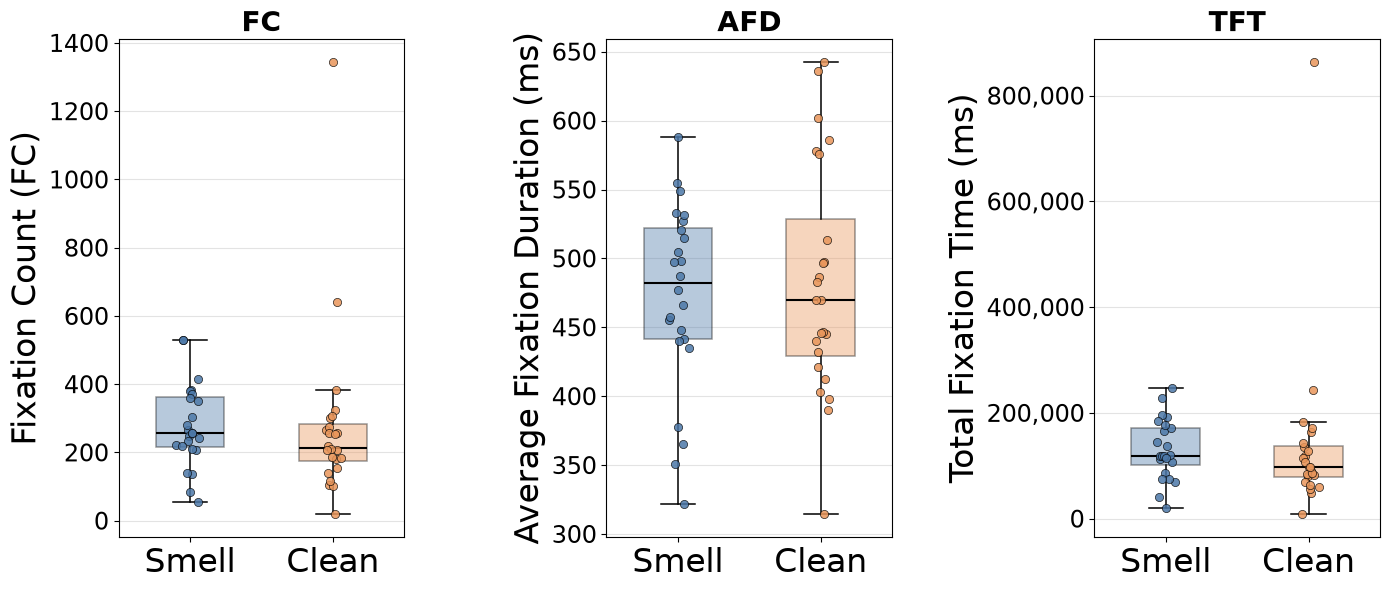

Saved to: /home/marioless/Documents/mestrado/EoS-tosem2026/metrics_update/outputs/rq2/smell_clean_fixation_metrics.pdf


In [8]:
import matplotlib.ticker as mticker

# ------------------------------------------------------------
# Boxplots — Smell vs. Clean
# ------------------------------------------------------------

PLOT_METRICS = {
    "FC": {
        "pairs": smell_clean_pairs["FC"],
        "ylabel": "Fixation Count (FC)",
    },
    "AFD": {
        "pairs": smell_clean_pairs["AFD (ms)"],
        "ylabel": "Average Fixation Duration (ms)",
    },
    "TFT": {
        "pairs": smell_clean_pairs["TFT (ms)"],
        "ylabel": "Total Fixation Time (ms)",
    },
}

fig, axes = plt.subplots(
    1,
    3,
    figsize=(14, 6),
)

colors = ["#4C78A8", "#E9965B"]

rng = np.random.default_rng(SEED)

for ax, (metric_name, info) in zip(axes, PLOT_METRICS.items()):

    pairs = info["pairs"]

    smell = pairs["value_a"].to_numpy()
    clean = pairs["value_b"].to_numpy()

    data = [smell, clean]

    box = ax.boxplot(
        data,
        positions=[1, 2],
        widths=0.48,
        patch_artist=True,
        showfliers=False,
        medianprops={
            "color": "black",
            "linewidth": 1.5,
        },
        whiskerprops={
            "color": "black",
            "linewidth": 1.1,
        },
        capprops={
            "color": "black",
            "linewidth": 1.1,
        },
        boxprops={
            "color": "black",
            "linewidth": 1.1,
        },
    )

    for patch, color in zip(box["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.40)

    jitter_smell = rng.normal(0, 0.035, len(smell))
    jitter_clean = rng.normal(0, 0.035, len(clean))

    ax.scatter(
        1 + jitter_smell,
        smell,
        s=35,
        alpha=0.85,
        color=colors[0],
        edgecolor="black",
        linewidth=0.5,
        zorder=3,
    )

    ax.scatter(
        2 + jitter_clean,
        clean,
        s=35,
        alpha=0.85,
        color=colors[1],
        edgecolor="black",
        linewidth=0.5,
        zorder=3,
    )

    ax.set_xticks([1, 2])
    ax.set_xticklabels(
        ["Smell", "Clean"],
        fontsize=24,
    )

    ax.set_ylabel(
        info["ylabel"],
        fontsize=24,
    )

    ax.set_title(
        metric_name,
        fontsize=20,
        fontweight="bold",
    )

    ax.tick_params(axis="y", labelsize=17)

    if metric_name == "TFT":
        # Thousands separator instead of scientific notation (values in ms, as in the tables)
        ax.yaxis.set_major_formatter(
            mticker.FuncFormatter(lambda value, _: f"{value:,.0f}")
        )

    ax.grid(
        axis="y",
        alpha=0.35,
        linewidth=0.8,
    )

    ax.set_axisbelow(True)


fig.tight_layout(w_pad=4)

output_path = OUTPUT_DIR / "smell_clean_fixation_metrics.pdf"

fig.savefig(
    output_path,
    format="pdf",
    bbox_inches="tight",
)

plt.show()

print("Saved to:", output_path.resolve())

### Table 6 — Paired Yuen test and $\hat p$

$\Delta = \text{Smell} - \text{Clean}$; positive values indicate a larger metric in the `Smell` condition.

$H_0$: the trimmed means do not differ between the two conditions.

In [9]:
smell_clean_results = pd.DataFrame(
    [compare_paired(pairs, label) for label, pairs in smell_clean_pairs.items()]
).rename(columns={"comparison": "metric"})

table_6 = pd.DataFrame(
    {
        "Metric": smell_clean_results["metric"],
        "n": smell_clean_results["n"],
        "Δ Trimmed Mean": smell_clean_results["delta"].map(lambda v: f"{v:,.2f}"),
        "95% CI Δ": [
            format_interval(row["ci_low"], row["ci_high"])
            for _, row in smell_clean_results.iterrows()
        ],
        "t (df)": [
            f"{row['t']:.2f} ({int(row['df'])})" for _, row in smell_clean_results.iterrows()
        ],
        "p": smell_clean_results["p_value"].map(lambda v: f"{v:.4f}"),
        "p-hat": smell_clean_results["phat"].map(lambda v: f"{v:.2f}"),
        "95% CI p-hat": [
            format_interval(row["phat_ci_low"], row["phat_ci_high"])
            for _, row in smell_clean_results.iterrows()
        ],
    }
)

display(table_6)

,Metric,n,Δ Trimmed Mean,95% CI Δ,t (df),p,p-hat,95% CI p-hat
0,FC,24,50.52,"[8.97, 92.07]",2.59 (15),0.0204,0.71,"[0.54, 0.88]"
1,AFD (ms),24,5.46,"[-26.82, 37.73]",0.36 (15),0.7235,0.42,"[0.21, 0.62]"
2,TFT (ms),24,"25,429.88","[5,948.60, 44,911.17]",2.78 (15),0.0139,0.71,"[0.54, 0.88]"


---
## 4. Section 4.2.2 — TFT across perceived code-smell types

Five perceived categories are considered: `LM`, `DC`, `FE`, `Others`, and `None`. Because participants could report more than one smell for the same snippet, the smell categories are **not mutually exclusive**, and the same `participant × snippet` cell may contribute to more than one category. Consequently, the paired sample size can vary across contrasts.

Only **TFT** is analyzed in this subsection. The ten pairwise contrasts constitute one family, and the false discovery rate is controlled with the Benjamini--Hochberg procedure across the ten p-values.

In [10]:
PERCEIVED_TYPE_COLUMNS = {
    "LM": "perceived_lm",
    "DC": "perceived_dc",
    "FE": "perceived_fe",
    "Others": "perceived_other",
}

blocks = [
    snippet_metrics.loc[
        pd.to_numeric(snippet_metrics[column], errors="coerce").eq(1)
    ].assign(perceived_type=smell_type)
    for smell_type, column in PERCEIVED_TYPE_COLUMNS.items()
]

blocks.append(
    snippet_metrics.loc[snippet_metrics["perceived_group"].eq("Clean")].assign(
        perceived_type="None"
    )
)

perceived_long = pd.concat(blocks, ignore_index=True)

multi_label = (
    snippet_metrics[list(PERCEIVED_TYPE_COLUMNS.values())]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
    .sum(axis=1)
    .gt(1)
)

print(f"Cells with more than one perceived smell type: {int(multi_label.sum())}")

display(perceived_long["perceived_type"].value_counts().to_frame("snippets"))

Cells with more than one perceived smell type: 13


,snippets
perceived_type,
None,141
LM,47
Others,43
DC,37
FE,31


### Table 7 — Paired TFT contrasts

$\Delta = A - B$; positive values indicate larger TFT in group A.

In [11]:
COMPARISONS = [
    ("LM", "DC"),
    ("LM", "FE"),
    ("DC", "FE"),
    ("LM", "None"),
    ("DC", "None"),
    ("FE", "None"),
    ("LM", "Others"),
    ("DC", "Others"),
    ("FE", "Others"),
    ("None", "Others"),
]

perceived_type_results = pd.DataFrame(
    [
        compare_paired(
            participant_pairs(
                perceived_long,
                group_col="perceived_type",
                metric_col="tft",
                group_a=group_a,
                group_b=group_b,
            ),
            f"{group_a} vs. {group_b}",
        )
        for group_a, group_b in COMPARISONS
    ]
)

perceived_type_results["p_fdr"] = benjamini_hochberg(perceived_type_results["p_value"])

table_7 = pd.DataFrame(
    {
        "Comparison": perceived_type_results["comparison"],
        "n": perceived_type_results["n"],
        "Δ Trimmed Mean": perceived_type_results["delta"].map(lambda v: f"{v:,.2f}"),
        "95% CI Δ": [
            format_interval(row["ci_low"], row["ci_high"])
            for _, row in perceived_type_results.iterrows()
        ],
        "p": perceived_type_results["p_value"].map(lambda v: f"{v:.4f}"),
        "p_FDR": perceived_type_results["p_fdr"].map(lambda v: f"{v:.4f}"),
        "p-hat": perceived_type_results["phat"].map(lambda v: f"{v:.2f}"),
        "95% CI p-hat": [
            format_interval(row["phat_ci_low"], row["phat_ci_high"])
            for _, row in perceived_type_results.iterrows()
        ],
    }
)

display(table_7)

,Comparison,n,Δ Trimmed Mean,95% CI Δ,p,p_FDR,p-hat,95% CI p-hat
0,LM vs. DC,17,"63,182.09","[25,890.15, 100,474.03]",0.0036,0.0121,0.82,"[0.65, 1.00]"
1,LM vs. FE,14,"44,764.01","[-35,768.74, 125,296.76]",0.2403,0.3432,0.64,"[0.36, 0.86]"
2,DC vs. FE,13,"-33,057.72","[-118,823.13, 52,707.69]",0.4000,0.5000,0.38,"[0.15, 0.69]"
3,LM vs. None,20,"29,354.16","[12,795.14, 45,913.19]",0.0025,0.0121,0.85,"[0.70, 1.00]"
4,DC vs. None,19,"-28,224.98","[-55,767.06, -682.90]",0.0454,0.1134,0.32,"[0.11, 0.53]"
5,FE vs. None,15,"-15,375.51","[-67,185.82, 36,434.80]",0.5131,0.5701,0.53,"[0.27, 0.80]"
6,LM vs. Others,15,"2,955.85","[-35,032.59, 40,944.29]",0.8621,0.8621,0.53,"[0.27, 0.80]"
7,DC vs. Others,14,"-67,116.23","[-105,601.99, -28,630.47]",0.0034,0.0121,0.14,"[0.00, 0.36]"
8,FE vs. Others,11,"-39,785.16","[-90,276.18, 10,705.87]",0.1021,0.1702,0.18,"[0.00, 0.45]"
9,None vs. Others,19,"-28,970.99","[-61,092.16, 3,150.18]",0.0730,0.1460,0.37,"[0.16, 0.58]"


In [12]:
significant = perceived_type_results.loc[perceived_type_results["p_fdr"].lt(ALPHA)]

print(f"Contrasts with p_FDR < {ALPHA}: {len(significant)}")

for _, row in significant.iterrows():
    print(
        f"  {row['comparison']:<16} Δ = {row['delta']:>12,.2f} ms"
        f"   p_FDR = {row['p_fdr']:.4f}   p-hat = {row['phat']:.2f}"
    )

Contrasts with p_FDR < 0.05: 3
  LM vs. DC        Δ =    63,182.09 ms   p_FDR = 0.0121   p-hat = 0.82
  LM vs. None      Δ =    29,354.16 ms   p_FDR = 0.0121   p-hat = 0.85
  DC vs. Others    Δ =   -67,116.23 ms   p_FDR = 0.0121   p-hat = 0.14


---
## 5. Section 4.2.3 — Agreement with MLCQ reference labels

MLCQ is treated as a **reference label**, not as objective ground truth. We therefore use the terms
`MLCQ-consistent` and `MLCQ-inconsistent`.

- For an MLCQ snippet labeled with a smell, a participant classification is **consistent** when the MLCQ-indicated smell is among the smells reported by the participant.
- For an MLCQ snippet labeled `None`, a participant classification is **consistent** when the participant reports no code smell.

In [13]:
SMELL_LABELS = {
    "long method": "LM",
    "data class": "DC",
    "feature envy": "FE",
}

agreement = snippet_metrics.copy()

smell_mlcq = agreement["smell_mlcq"].astype(str).str.strip().str.lower()
severity_mlcq = agreement["severity_mlcq"].astype(str).str.strip().str.lower()
reported_no_smell = agreement["perceived_group"].eq("Clean")

# MLCQ reference label for the participant × snippet cell.
agreement["mlcq_label"] = np.where(
    severity_mlcq.eq("none"),
    "None",
    smell_mlcq.map(SMELL_LABELS),
)

# Did the participant report the smell indicated by MLCQ?
identified_expected = np.select(
    [smell_mlcq.eq(name) for name in SMELL_LABELS],
    [
        pd.to_numeric(agreement[column], errors="coerce").eq(1)
        for column in ["perceived_lm", "perceived_dc", "perceived_fe"]
    ],
    default=False,
)

agreement["agreement"] = np.where(
    agreement["perceived_group"].isna(),
    None,
    np.where(
        np.where(severity_mlcq.eq("none"), reported_no_smell, identified_expected),
        "consistent",
        "inconsistent",
    ),
)

display(agreement["agreement"].value_counts(dropna=False).to_frame("snippets"))

,snippets
agreement,
inconsistent,170
consistent,114
NaN,13


### Table 8 — Multilabel one-vs-rest confusion matrix

A conventional 4×4 confusion matrix would be inappropriate because participants could report more than one smell for the same snippet. For `LM`, `DC`, and `FE`, a positive prediction means that the participant reported the corresponding smell. For `None`, a positive prediction means that the participant reported no code smell.

In [14]:
classified = agreement.loc[agreement["agreement"].notna()]

PREDICTION_COLUMNS = {
    "LM": "perceived_lm",
    "DC": "perceived_dc",
    "FE": "perceived_fe",
}

confusion_rows = []

for label in ["LM", "DC", "FE", "None"]:
    actual_positive = classified["mlcq_label"].eq(label)

    predicted_positive = (
        classified["perceived_group"].eq("Clean")
        if label == "None"
        else pd.to_numeric(classified[PREDICTION_COLUMNS[label]], errors="coerce").eq(1)
    )

    confusion_rows.append(
        {
            "MLCQ label": label,
            "TP": int((actual_positive & predicted_positive).sum()),
            "FN": int((actual_positive & ~predicted_positive).sum()),
            "FP": int((~actual_positive & predicted_positive).sum()),
            "TN": int((~actual_positive & ~predicted_positive).sum()),
        }
    )

table_8 = pd.DataFrame(confusion_rows)

print(f"Participant × snippet observations with usable classifications: {len(classified)}")

display(table_8)

Participant × snippet observations with usable classifications: 284


,MLCQ label,TP,FN,FP,TN
0,LM,34,36,13,201
1,DC,28,43,9,204
2,FE,6,66,25,187
3,None,46,25,95,118


### TFT: MLCQ-consistent vs. MLCQ-inconsistent

$\Delta = \text{consistent} - \text{inconsistent}$; negative values indicate larger TFT for MLCQ-inconsistent classifications.

This is a single planned contrast, so no multiple-comparison adjustment is applied.

In [15]:
AGREEMENT_METRICS = {
    "FC": "fc",
    "AFD (ms)": "afd",
    "TFT (ms)": "tft",
}

agreement_pairs = {
    label: participant_pairs(
        agreement,
        group_col="agreement",
        metric_col=column,
        group_a="consistent",
        group_b="inconsistent",
    )
    for label, column in AGREEMENT_METRICS.items()
}

for metric, pairs in agreement_pairs.items():
    print(
        f"{metric}: {len(pairs)} participants with valid pairs"
    )

FC: 24 participants with valid pairs
AFD (ms): 24 participants with valid pairs
TFT (ms): 24 participants with valid pairs


In [16]:
agreement_descriptive = pd.DataFrame(
    [
        {
            "Condition": "MLCQ-consistent",
            "FC — Median [IQR]": median_iqr(
                agreement_pairs["FC"]["value_a"]
            ),
            "AFD — Median [IQR] (ms)": median_iqr(
                agreement_pairs["AFD (ms)"]["value_a"]
            ),
            "TFT — Median [IQR] (ms)": median_iqr(
                agreement_pairs["TFT (ms)"]["value_a"]
            ),
        },
        {
            "Condition": "MLCQ-inconsistent",
            "FC — Median [IQR]": median_iqr(
                agreement_pairs["FC"]["value_b"]
            ),
            "AFD — Median [IQR] (ms)": median_iqr(
                agreement_pairs["AFD (ms)"]["value_b"]
            ),
            "TFT — Median [IQR] (ms)": median_iqr(
                agreement_pairs["TFT (ms)"]["value_b"]
            ),
        },
    ]
)

display(agreement_descriptive)

,Condition,FC — Median [IQR],AFD — Median [IQR] (ms),TFT — Median [IQR] (ms)
0,MLCQ-consistent,"217.00 [159.50, 276.35]","483.40 [435.62, 524.76]","104,316.17 [82,421.60, 135,391.50]"
1,MLCQ-inconsistent,"262.67 [184.95, 333.55]","483.66 [433.73, 526.54]","117,980.50 [85,025.18, 168,743.35]"


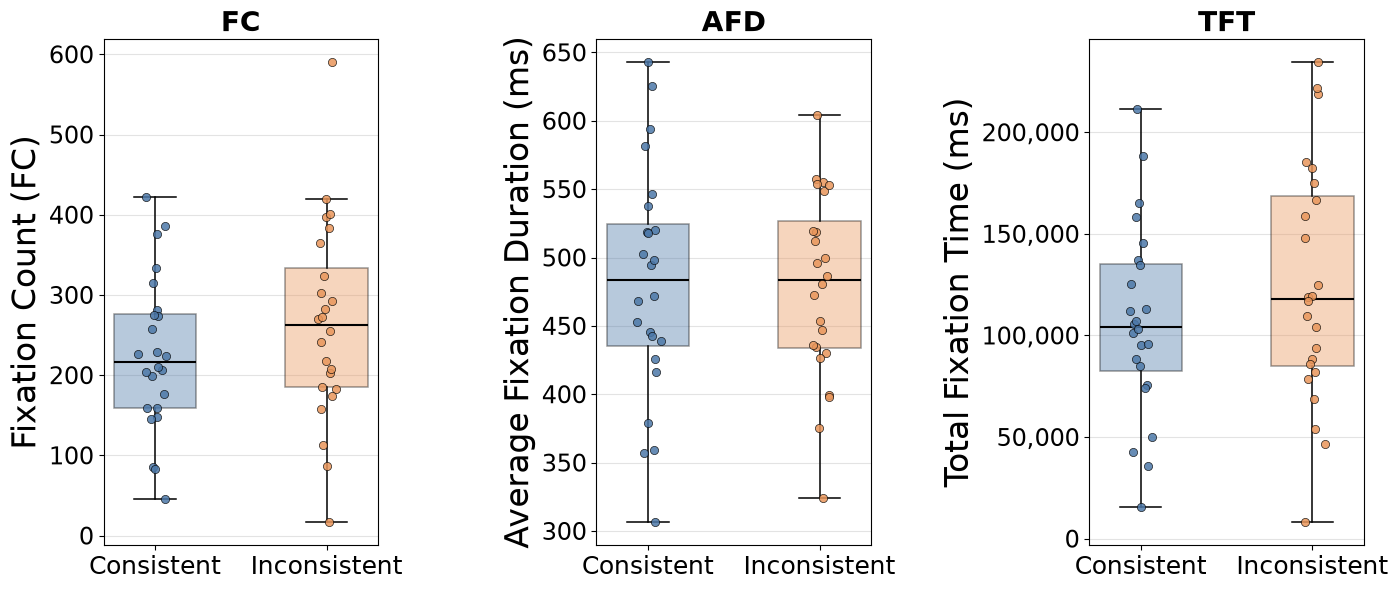

Saved to: /home/marioless/Documents/mestrado/EoS-tosem2026/metrics_update/outputs/rq2/mlcq_agreement_fixation_metrics.pdf


In [17]:
# ------------------------------------------------------------
# Boxplots — MLCQ-consistent vs. MLCQ-inconsistent
# ------------------------------------------------------------

AGREEMENT_PLOT_METRICS = {
    "FC": {
        "pairs": agreement_pairs["FC"],
        "ylabel": "Fixation Count (FC)",
    },
    "AFD": {
        "pairs": agreement_pairs["AFD (ms)"],
        "ylabel": "Average Fixation Duration (ms)",
    },
    "TFT": {
        "pairs": agreement_pairs["TFT (ms)"],
        "ylabel": "Total Fixation Time (ms)",
    },
}

fig, axes = plt.subplots(
    1,
    3,
    figsize=(14, 6),
)

colors = ["#4C78A8", "#E9965B"]

rng = np.random.default_rng(SEED)

for ax, (metric_name, info) in zip(
    axes,
    AGREEMENT_PLOT_METRICS.items(),
):

    pairs = info["pairs"]

    consistent = pairs["value_a"].to_numpy()
    inconsistent = pairs["value_b"].to_numpy()

    data = [
        consistent,
        inconsistent,
    ]

    box = ax.boxplot(
        data,
        positions=[1, 2],
        widths=0.48,
        patch_artist=True,
        showfliers=False,
        medianprops={
            "color": "black",
            "linewidth": 1.5,
        },
        whiskerprops={
            "color": "black",
            "linewidth": 1.1,
        },
        capprops={
            "color": "black",
            "linewidth": 1.1,
        },
        boxprops={
            "color": "black",
            "linewidth": 1.1,
        },
    )

    for patch, color in zip(box["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.40)

    jitter_consistent = rng.normal(
        0,
        0.035,
        len(consistent),
    )

    jitter_inconsistent = rng.normal(
        0,
        0.035,
        len(inconsistent),
    )

    ax.scatter(
        1 + jitter_consistent,
        consistent,
        s=35,
        alpha=0.85,
        color=colors[0],
        edgecolor="black",
        linewidth=0.5,
        zorder=3,
    )

    ax.scatter(
        2 + jitter_inconsistent,
        inconsistent,
        s=35,
        alpha=0.85,
        color=colors[1],
        edgecolor="black",
        linewidth=0.5,
        zorder=3,
    )

    ax.set_xticks([1, 2])
    # Tight x-limits push the two boxes apart so the category labels do not touch
    ax.set_xlim(0.7, 2.3)
    ax.set_xticklabels(
        [
            "Consistent",
            "Inconsistent",
        ],
        fontsize=18,
    )

    ax.set_ylabel(
        info["ylabel"],
        fontsize=24,
    )

    ax.set_title(
        metric_name,
        fontsize=20,
        fontweight="bold",
    )

    ax.tick_params(axis="y", labelsize=17)

    if metric_name == "TFT":
        # Thousands separator instead of scientific notation (values in ms, as in the tables)
        ax.yaxis.set_major_formatter(
            mticker.FuncFormatter(lambda value, _: f"{value:,.0f}")
        )

    ax.grid(
        axis="y",
        alpha=0.35,
        linewidth=0.8,
    )

    ax.set_axisbelow(True)


fig.tight_layout(w_pad=4)

output_path = (
    OUTPUT_DIR
    / "mlcq_agreement_fixation_metrics.pdf"
)

fig.savefig(
    output_path,
    format="pdf",
    bbox_inches="tight",
)

plt.show()

print("Saved to:", output_path.resolve())

In [18]:
agreement_results = pd.DataFrame(
    [
        compare_paired(pairs, label)
        for label, pairs in agreement_pairs.items()
    ]
).rename(columns={"comparison": "metric"})

agreement_table = pd.DataFrame(
    {
        "Metric": agreement_results["metric"],
        "n": agreement_results["n"],
        "Δ Trimmed Mean": agreement_results["delta"].map(
            lambda v: f"{v:,.2f}"
        ),
        "95% CI Δ": [
            format_interval(row["ci_low"], row["ci_high"])
            for _, row in agreement_results.iterrows()
        ],
        "t (df)": [
            f"{row['t']:.2f} ({int(row['df'])})"
            for _, row in agreement_results.iterrows()
        ],
        "p": agreement_results["p_value"].map(
            lambda v: f"{v:.4f}"
        ),
        "p-hat": agreement_results["phat"].map(
            lambda v: f"{v:.2f}"
        ),
        "95% CI p-hat": [
            format_interval(
                row["phat_ci_low"],
                row["phat_ci_high"]
            )
            for _, row in agreement_results.iterrows()
        ],
    }
)

display(agreement_table)

,Metric,n,Δ Trimmed Mean,95% CI Δ,t (df),p,p-hat,95% CI p-hat
0,FC,24,-38.49,"[-84.15, 7.18]",-1.80 (15),0.0926,0.38,"[0.21, 0.58]"
1,AFD (ms),24,-1.06,"[-30.76, 28.64]",-0.08 (15),0.9404,0.54,"[0.33, 0.75]"
2,TFT (ms),24,"-15,933.33","[-35,013.94, 3,147.29]",-1.78 (15),0.0954,0.38,"[0.21, 0.58]"


---
## 6. Sensitivity analysis — size-normalized effort

The snippets differ in size, so a larger TFT could simply reflect more code to read. This sensitivity
analysis checks whether the primary conclusions (Smell > Clean, and the perceived-type contrasts, in particular
LM vs. None) hold once code size is discounted. It does not replace the primary analysis.

**Scope.** The primary TFT includes fixations outside the target code. Dividing that total by the size of the
target code would mix numerator and denominator of different scopes, so only fixations **inside the target
code** are normalized. The target code is the region between the `CODE SNIPPET STARTS/ENDS HERE` markers of
the displayed file, because fixation line numbers refer to the displayed file (the MLCQ `start_line`/`end_line`
are offset by the marker line).

**Measures** (per `participant × snippet` cell):

$$TFT_{line} = \frac{TFT_{inside}}{LOC}, \qquad
TFT_{token} = \frac{TFT_{inside}}{\text{tokens}}, \qquad
FC_{line} = \frac{FC_{inside}}{LOC},$$

where LOC is the number of non-blank lines of the target code and tokens is the number of lexical Java tokens
(comments excluded), the alternative normalizer because long lines weigh more. AFD is not normalized: it is a
mean per fixation and does not grow with the amount of code.

**Inference.** Same pipeline as above (participant-level aggregation, paired Yuen with 20% trimming,
$\hat p$ with bootstrap CI). Each block is its own Benjamini--Hochberg family:

| Block | Tests | FDR family |
|---|---|---|
| Smell vs. Clean | $TFT_{line}$, $TFT_{token}$, $FC_{line}$ | one family of 3 |
| Perceived types — $TFT_{line}$ | 10 contrasts | one family of 10 |
| Perceived types — $TFT_{token}$ | 10 contrasts | one family of 10 |
| MLCQ-consistent vs. inconsistent | $TFT_{line}$, $TFT_{token}$ | single planned contrasts, unadjusted (as in Section 5) |

In [19]:
from snippet_characteristics import snippet_sizes

sizes = snippet_sizes()

region = fixations[["snippet_id", "source_file_line"]].merge(
    sizes[["snippet_id", "region_start", "region_end"]],
    on="snippet_id",
    how="left",
    validate="many_to_one",
)

fixations["inside_displayed"] = (
    region["source_file_line"].between(region["region_start"], region["region_end"]).to_numpy()
)

inside_metrics = (
    fixations.loc[fixations["inside_displayed"]]
    .groupby(KEY)
    .agg(fc_inside=("duration", "size"), tft_inside=("duration", "sum"))
)

normalized = (
    snippet_metrics.drop(columns=["fc_inside", "tft_inside"], errors="ignore")
    .merge(inside_metrics, on=KEY, how="left")
    .merge(sizes[["snippet_id", "loc", "n_tokens"]], on="snippet_id", how="left", validate="many_to_one")
)

# Cells whose fixations all fall outside the target code have zero inside effort.
normalized[["fc_inside", "tft_inside"]] = normalized[["fc_inside", "tft_inside"]].fillna(0)

normalized["tft_per_line"] = normalized["tft_inside"] / normalized["loc"]
normalized["tft_per_token"] = normalized["tft_inside"] / normalized["n_tokens"]
normalized["fc_per_line"] = normalized["fc_inside"] / normalized["loc"]

print(f"Share of TFT inside the target code: {normalized['tft_inside'].sum() / normalized['tft'].sum():.1%}")
print(f"Cells with no fixation inside      : {int(normalized['fc_inside'].eq(0).sum())}")

display(sizes)

Share of TFT inside the target code: 87.5%
Cells with no fixation inside      : 0


,snippet_id,region_start,region_end,loc,n_tokens,n_chars,file_loc
0,2,74,94,21,178,669,82
1,3,19,40,16,66,296,32
2,4,104,117,14,42,268,172
3,5,190,226,36,126,737,355
4,6,149,166,16,90,293,144
5,7,21,55,29,75,480,46
6,8,29,52,19,78,462,44
7,9,574,612,35,288,1343,2593
8,10,151,164,11,91,342,731
9,11,441,471,30,237,1020,620


### 6.1 Smell vs. Clean

$\Delta = \text{Smell} - \text{Clean}$. The raw $TFT_{inside}$ is shown for reference only (not part of the
FDR family), to separate the effect of restricting the scope from the effect of normalizing.

In [20]:
NORMALIZED_METRICS = {
    "TFT per line (ms/line)": "tft_per_line",
    "TFT per token (ms/token)": "tft_per_token",
    "FC per line (fixations/line)": "fc_per_line",
}

REFERENCE_METRICS = {"TFT inside (ms)": "tft_inside"}


def run_normalized_family(data, group_col, group_a, group_b, metrics, family):
    # Paired Yuen + p-hat per metric, BH-adjusted within the family.
    results = pd.DataFrame(
        [
            {
                "family": family,
                "metric": label,
                **compare_paired(
                    participant_pairs(data, group_col, column, group_a, group_b),
                    f"{group_a} vs. {group_b}",
                ),
            }
            for label, column in metrics.items()
        ]
    )
    results["p_fdr"] = benjamini_hochberg(results["p_value"])

    return results


def format_normalized_table(results: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame(
        {
            "Metric": results["metric"],
            "Comparison": results["comparison"],
            "n": results["n"],
            "Δ Trimmed Mean": results["delta"].map(lambda v: f"{v:,.2f}"),
            "95% CI Δ": [format_interval(r["ci_low"], r["ci_high"]) for _, r in results.iterrows()],
            "p": results["p_value"].map(lambda v: f"{v:.4f}"),
            "p_FDR": results["p_fdr"].map(lambda v: f"{v:.4f}"),
            "p-hat": results["phat"].map(lambda v: f"{v:.2f}"),
            "95% CI p-hat": [
                format_interval(r["phat_ci_low"], r["phat_ci_high"]) for _, r in results.iterrows()
            ],
        }
    )


normalized_smell_clean = run_normalized_family(
    normalized, "perceived_group", "Smell", "Clean", NORMALIZED_METRICS,
    family="Size-normalized — Smell vs. Clean",
)

reference_smell_clean = run_normalized_family(
    normalized, "perceived_group", "Smell", "Clean", REFERENCE_METRICS,
    family="Reference — Smell vs. Clean",
)

display(format_normalized_table(pd.concat([reference_smell_clean, normalized_smell_clean], ignore_index=True)))

,Metric,Comparison,n,Δ Trimmed Mean,95% CI Δ,p,p_FDR,p-hat,95% CI p-hat
0,TFT inside (ms),Smell vs. Clean,24,"19,228.09","[4,355.64, 34,100.54]",0.0147,0.0147,0.71,"[0.50, 0.88]"
1,TFT per line (ms/line),Smell vs. Clean,24,306.32,"[-799.62, 1,412.26]",0.5637,0.8456,0.54,"[0.33, 0.75]"
2,TFT per token (ms/token),Smell vs. Clean,24,165.31,"[-14.12, 344.74]",0.0684,0.2051,0.62,"[0.42, 0.79]"
3,FC per line (fixations/line),Smell vs. Clean,24,0.14,"[-2.50, 2.78]",0.9129,0.9129,0.54,"[0.33, 0.75]"


### 6.2 Perceived code-smell types

The ten contrasts of Section 4 are repeated for $TFT_{line}$ and $TFT_{token}$, each normalizer forming its
own family of ten. The primary $p_{FDR}$ (raw TFT, Table 7) is shown alongside for comparison.

In [21]:
normalized_long = (
    perceived_long.drop(columns=["fc_inside", "tft_inside"], errors="ignore")
    .merge(
        normalized[KEY + ["tft_inside", "tft_per_line", "tft_per_token", "fc_per_line"]],
        on=KEY,
        how="left",
        validate="many_to_one",
    )
)

normalized_type_results = pd.concat(
    [
        pd.concat(
            [
                pd.DataFrame(
                    [
                        {
                            "family": f"Size-normalized — perceived types — {label}",
                            "metric": label,
                            **compare_paired(
                                participant_pairs(normalized_long, "perceived_type", column, a, b),
                                f"{a} vs. {b}",
                            ),
                        }
                        for a, b in COMPARISONS
                    ]
                )
            ]
        ).assign(p_fdr=lambda frame: benjamini_hochberg(frame["p_value"]))
        for label, column in {
            "TFT per line (ms/line)": "tft_per_line",
            "TFT per token (ms/token)": "tft_per_token",
        }.items()
    ],
    ignore_index=True,
)

type_comparison = (
    normalized_type_results.pivot(index="comparison", columns="metric", values="p_fdr")
    .rename(columns=lambda c: f"p_FDR — {c}")
    .join(
        perceived_type_results.set_index("comparison")["p_fdr"].rename("p_FDR — TFT (primary)")
    )
    .reindex([f"{a} vs. {b}" for a, b in COMPARISONS])
    [["p_FDR — TFT (primary)", "p_FDR — TFT per line (ms/line)", "p_FDR — TFT per token (ms/token)"]]
)

display(format_normalized_table(normalized_type_results))
display(type_comparison.round(4))

,Metric,Comparison,n,Δ Trimmed Mean,95% CI Δ,p,p_FDR,p-hat,95% CI p-hat
0,TFT per line (ms/line),LM vs. DC,17,655.10,"[-1,158.86, 2,469.07]",0.4397,0.6282,0.59,"[0.35, 0.82]"
1,TFT per line (ms/line),LM vs. FE,14,-215.90,"[-3,882.38, 3,450.58]",0.8970,0.8970,0.57,"[0.29, 0.86]"
2,TFT per line (ms/line),DC vs. FE,13,"-1,474.96","[-5,652.64, 2,702.71]",0.4391,0.6282,0.38,"[0.15, 0.62]"
3,TFT per line (ms/line),LM vs. None,20,-528.00,"[-1,473.95, 417.96]",0.2449,0.6275,0.40,"[0.20, 0.60]"
4,TFT per line (ms/line),DC vs. None,19,-809.20,"[-2,244.84, 626.45]",0.2430,0.6275,0.42,"[0.21, 0.63]"
5,TFT per line (ms/line),FE vs. None,15,-571.80,"[-4,191.53, 3,047.94]",0.7251,0.8057,0.40,"[0.13, 0.67]"
6,TFT per line (ms/line),LM vs. Others,15,"-1,215.80","[-3,765.68, 1,334.08]",0.3035,0.6275,0.53,"[0.27, 0.80]"
7,TFT per line (ms/line),DC vs. Others,14,"-2,376.66","[-4,727.63, -25.68]",0.0480,0.4802,0.29,"[0.07, 0.50]"
8,TFT per line (ms/line),FE vs. Others,11,"-1,579.77","[-5,096.07, 1,936.53]",0.3138,0.6275,0.45,"[0.18, 0.73]"
9,TFT per line (ms/line),None vs. Others,19,-648.66,"[-2,785.99, 1,488.67]",0.5209,0.6512,0.37,"[0.16, 0.58]"


,p_FDR — TFT (primary),p_FDR — TFT per line (ms/line),p_FDR — TFT per token (ms/token)
comparison,,,
LM vs. DC,0.0121,0.6282,0.6199
LM vs. FE,0.3432,0.8970,0.6184
DC vs. FE,0.5000,0.6282,0.6199
LM vs. None,0.0121,0.6275,0.1214
DC vs. None,0.1134,0.6275,0.6853
FE vs. None,0.5701,0.8057,0.6853
LM vs. Others,0.8621,0.6275,0.1214
DC vs. Others,0.0121,0.4802,0.0819
FE vs. Others,0.1702,0.6275,0.5868


### 6.3 MLCQ-consistent vs. MLCQ-inconsistent

$\Delta = \text{consistent} - \text{inconsistent}$. Single planned contrasts, as in Section 5; `p_FDR` is
reported but equals `p` when a family has one test.

In [22]:
normalized_agreement = agreement.merge(
    normalized[KEY + ["tft_per_line", "tft_per_token"]],
    on=KEY,
    how="left",
    validate="one_to_one",
)

normalized_agreement_results = pd.concat(
    [
        run_normalized_family(
            normalized_agreement, "agreement", "consistent", "inconsistent", {label: column},
            family=f"Size-normalized — MLCQ agreement — {label}",
        )
        for label, column in {
            "TFT per line (ms/line)": "tft_per_line",
            "TFT per token (ms/token)": "tft_per_token",
        }.items()
    ],
    ignore_index=True,
)

display(format_normalized_table(normalized_agreement_results))

,Metric,Comparison,n,Δ Trimmed Mean,95% CI Δ,p,p_FDR,p-hat,95% CI p-hat
0,TFT per line (ms/line),consistent vs. inconsistent,24,-576.49,"[-1,519.41, 366.43]",0.2122,0.2122,0.42,"[0.21, 0.62]"
1,TFT per token (ms/token),consistent vs. inconsistent,24,-174.06,"[-331.78, -16.33]",0.0327,0.0327,0.29,"[0.12, 0.50]"


### 6.4 Size and TFT across snippets (descriptive)

Spearman correlation between snippet size and the mean TFT of each snippet (mean over its
`participant × snippet` cells). With $n = 12$ snippets, the correlation is reported with its 95% CI, using the
Fisher $z$ transformation with the Bonett--Wright standard error $\sqrt{(1 + \rho^2/2)/(n - 3)}$; the p-value
is not interpreted.

In [23]:
from scipy.stats import norm, spearmanr


def spearman_ci(x, y, alpha: float = ALPHA) -> dict:
    rho = spearmanr(x, y).statistic
    n = len(x)
    se = np.sqrt((1 + rho**2 / 2) / (n - 3))
    z = np.arctanh(rho)
    critical = norm.ppf(1 - alpha / 2)

    return {
        "n_snippets": n,
        "rho": rho,
        "ci_low": np.tanh(z - critical * se),
        "ci_high": np.tanh(z + critical * se),
    }


snippet_effort = (
    normalized.groupby("snippet_id")[["tft", "tft_inside"]]
    .mean()
    .join(sizes.set_index("snippet_id")[["loc", "n_tokens"]])
)

size_correlations = pd.DataFrame(
    [
        {"size": size_label, "tft": tft_label, **spearman_ci(snippet_effort[size], snippet_effort[tft])}
        for size_label, size in {"LOC": "loc", "Tokens": "n_tokens"}.items()
        for tft_label, tft in {"Mean TFT (all fixations)": "tft", "Mean TFT inside": "tft_inside"}.items()
    ]
)

display(snippet_effort.round(1))
display(size_correlations.round(3))

,tft,tft_inside,loc,n_tokens
snippet_id,,,,
2,219606.4,202649.8,21,178
3,72821.4,67255.6,16,66
4,127681.4,88216.0,14,42
5,164872.3,138657.4,36,126
6,81632.7,74940.0,16,90
7,62862.9,56753.2,29,75
8,72323.6,67889.7,19,78
9,143953.7,132420.9,35,288
10,83757.4,60620.2,11,91


,size,tft,n_snippets,rho,ci_low,ci_high
0,LOC,Mean TFT (all fixations),12,0.179,-0.445,0.685
1,LOC,Mean TFT inside,12,0.420,-0.229,0.811
2,Tokens,Mean TFT (all fixations),12,0.616,0.007,0.892
3,Tokens,Mean TFT inside,12,0.701,0.138,0.921


In [24]:
# ------------------------------------------------------------
# LaTeX table — size-normalized sensitivity
# ------------------------------------------------------------

def latex_row(row) -> str:
    return (
        f"{row['comparison']} & {row['n']} & {row['delta']:,.2f} & "
        f"[{row['ci_low']:,.2f}, {row['ci_high']:,.2f}] & {row['p_fdr']:.4f} & "
        f"{row['phat']:.2f} [{row['phat_ci_low']:.2f}, {row['phat_ci_high']:.2f}] \\\\"
    )


SENSITIVITY_BLOCKS = [
    ("Smell vs. Clean", normalized_smell_clean),
    ("Perceived types", normalized_type_results),
]

latex_blocks = []

for block_name, results in SENSITIVITY_BLOCKS:
    for metric, group in results.groupby("metric", sort=False):
        latex_blocks.append(
            f"\\multicolumn{{6}}{{l}}{{\\textit{{{block_name} --- {metric}}}}} \\\\\n"
            + "\n".join(latex_row(row) for _, row in group.iterrows())
        )

latex_body = "\n\\midrule\n".join(latex_blocks)

size_normalized_tex = rf"""\begin{{table}}[ht]
\centering
\caption{{Sensitivity of the RQ2 results to code size. Only fixations inside the target code are used,
divided by its non-blank LOC (per line) or by its number of Java tokens (per token). $\Delta$ = difference in
20\% trimmed means (paired Yuen test); $p_{{FDR}}$ = Benjamini--Hochberg adjusted within each block;
$\hat p$ = paired probability of superiority with 95\% bootstrap CI.}}
\label{{tab:rq2_size_normalized}}
\scriptsize
\begin{{tabular}}{{lrrlrl}}
\toprule
Comparison & $n$ & $\Delta$ & 95\% CI $\Delta$ & $p_{{FDR}}$ & $\hat p$ [95\% CI] \\
\midrule
{latex_body}
\bottomrule
\end{{tabular}}
\end{{table}}
"""

(OUTPUT_DIR / "rq2_size_normalized_sensitivity.tex").write_text(size_normalized_tex, encoding="utf-8")
print(size_normalized_tex)

\begin{table}[ht]
\centering
\caption{Sensitivity of the RQ2 results to code size. Only fixations inside the target code are used,
divided by its non-blank LOC (per line) or by its number of Java tokens (per token). $\Delta$ = difference in
20\% trimmed means (paired Yuen test); $p_{FDR}$ = Benjamini--Hochberg adjusted within each block;
$\hat p$ = paired probability of superiority with 95\% bootstrap CI.}
\label{tab:rq2_size_normalized}
\scriptsize
\begin{tabular}{lrrlrl}
\toprule
Comparison & $n$ & $\Delta$ & 95\% CI $\Delta$ & $p_{FDR}$ & $\hat p$ [95\% CI] \\
\midrule
\multicolumn{6}{l}{\textit{Smell vs. Clean --- TFT per line (ms/line)}} \\
Smell vs. Clean & 24 & 306.32 & [-799.62, 1,412.26] & 0.8456 & 0.54 [0.33, 0.75] \\
\midrule
\multicolumn{6}{l}{\textit{Smell vs. Clean --- TFT per token (ms/token)}} \\
Smell vs. Clean & 24 & 165.31 & [-14.12, 344.74] & 0.2051 & 0.62 [0.42, 0.79] \\
\midrule
\multicolumn{6}{l}{\textit{Smell vs. Clean --- FC per line (fixations/line)}} \\
Smell

---
## 7. Export results

In [25]:
EXPORTS = {
    "table5_smell_clean_descriptive.csv": table_5,
    "table6_smell_clean_yuen_phat.csv": table_6,
    "table7_perceived_smell_types_tft.csv": table_7,
    "table8_mlcq_confusion.csv": table_8,
    "mlcq_agreement_tft_descriptive.csv": agreement_descriptive,
    "mlcq_agreement_tft_yuen_phat.csv": agreement_results,
    "raw_smell_clean_results.csv": smell_clean_results,
    "raw_perceived_type_results.csv": perceived_type_results,
    "rq2_snippet_metrics.csv": snippet_metrics,
    "rq2_snippet_sizes.csv": sizes,
    "rq2_size_normalized_metrics.csv": normalized,
    "rq2_size_normalized_smell_clean.csv": pd.concat([reference_smell_clean, normalized_smell_clean], ignore_index=True),
    "rq2_size_normalized_types.csv": normalized_type_results,
    "rq2_size_normalized_types_vs_primary.csv": type_comparison.reset_index(),
    "rq2_size_normalized_mlcq_agreement.csv": normalized_agreement_results,
    "rq2_size_tft_spearman.csv": size_correlations,
}

for filename, frame in EXPORTS.items():
    frame.to_csv(OUTPUT_DIR / filename, index=False)
    print("Saved:", (OUTPUT_DIR / filename).name)

Saved: table5_smell_clean_descriptive.csv
Saved: table6_smell_clean_yuen_phat.csv
Saved: table7_perceived_smell_types_tft.csv
Saved: table8_mlcq_confusion.csv
Saved: mlcq_agreement_tft_descriptive.csv
Saved: mlcq_agreement_tft_yuen_phat.csv
Saved: raw_smell_clean_results.csv
Saved: raw_perceived_type_results.csv
Saved: rq2_snippet_metrics.csv
Saved: rq2_snippet_sizes.csv
Saved: rq2_size_normalized_metrics.csv
Saved: rq2_size_normalized_smell_clean.csv
Saved: rq2_size_normalized_types.csv
Saved: rq2_size_normalized_types_vs_primary.csv
Saved: rq2_size_normalized_mlcq_agreement.csv
Saved: rq2_size_tft_spearman.csv
